/odom: 948 msgs, /cmd_vel: 3469 msgs, duration: 47.4 s


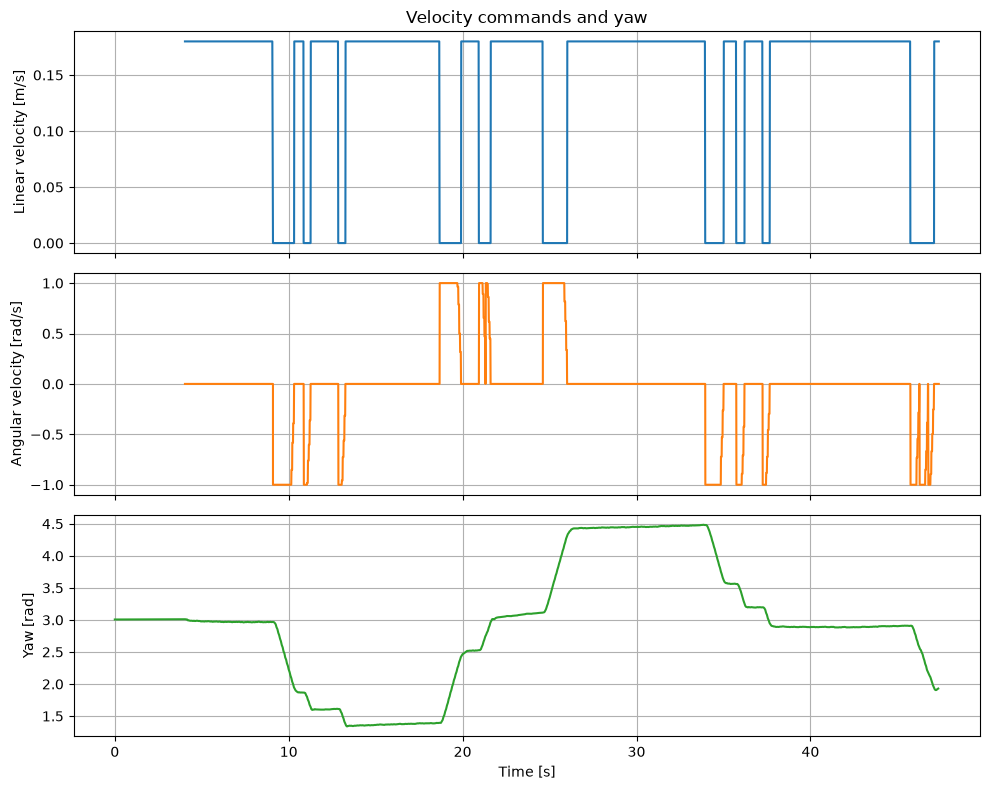

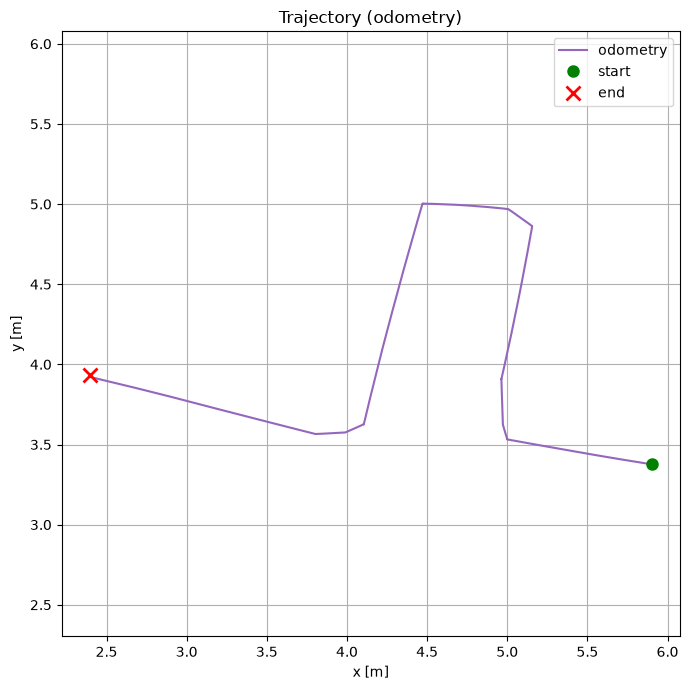

In [9]:
# %% [markdown]
# # Plot a ROS 2 bag (.db3) with matplotlib
# Needs only: pip install rosbags numpy matplotlib
# Reads the .db3 file directly (metadata.yaml is not needed).

# %% Imports and configuration
import sqlite3
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from rosbags.typesys import Stores, get_typestore

DB3_PATH = Path('./lab03_final_result_0.db3')   # <-- change to your file
SAVE_FIGURES = True

typestore = get_typestore(Stores.ROS2_HUMBLE)


# %% Helper to read one topic
def read_topic(con, topic):
    """Return a list of (time_in_seconds, message) for the given topic."""
    cur = con.cursor()
    row = cur.execute('SELECT id, type FROM topics WHERE name=?', (topic,)).fetchone()
    if row is None:
        raise KeyError(f'Topic {topic} not found in the bag')
    topic_id, msg_type = row
    rows = cur.execute(
        'SELECT timestamp, data FROM messages WHERE topic_id=? ORDER BY timestamp',
        (topic_id,))
    return [(t * 1e-9, typestore.deserialize_cdr(bytes(d), msg_type)) for t, d in rows]


# %% Load data
con = sqlite3.connect(str(DB3_PATH))
odom = read_topic(con, '/odom')
cmd = read_topic(con, '/cmd_vel')
con.close()

t0 = min(odom[0][0], cmd[0][0])          # common time origin

# --- odometry: position and yaw ---
t_o = np.array([t - t0 for t, _ in odom])
x = np.array([m.pose.pose.position.x for _, m in odom])
y = np.array([m.pose.pose.position.y for _, m in odom])
q = [m.pose.pose.orientation for _, m in odom]
yaw = np.array([np.arctan2(2 * (o.w * o.z + o.x * o.y),
                           1 - 2 * (o.y ** 2 + o.z ** 2)) for o in q])
yaw_unwrapped = np.unwrap(yaw)           # continuous heading, no +-pi jumps

# --- velocity commands ---
t_c = np.array([t - t0 for t, _ in cmd])
v = np.array([m.linear.x for _, m in cmd])
w = np.array([m.angular.z for _, m in cmd])

print(f'/odom: {len(odom)} msgs, /cmd_vel: {len(cmd)} msgs, '
      f'duration: {max(t_o[-1], t_c[-1]):.1f} s')


# %% Figure 1: three signals, one above the other
fig1, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

axs[0].plot(t_c, v, color='tab:blue')
axs[0].set_ylabel('Linear velocity [m/s]')
axs[0].set_title('Velocity commands and yaw')

axs[1].plot(t_c, w, color='tab:orange')
axs[1].set_ylabel('Angular velocity [rad/s]')

axs[2].plot(t_o, yaw_unwrapped, color='tab:green')
axs[2].set_ylabel('Yaw [rad]')
axs[2].set_xlabel('Time [s]')

for ax in axs:
    ax.grid(True)
fig1.tight_layout()
if SAVE_FIGURES:
    fig1.savefig('signals.png', dpi=150)


# %% Figure 2: XY trajectory
fig2, ax2 = plt.subplots(figsize=(7, 7))
ax2.plot(x, y, color='tab:purple', label='odometry')
ax2.plot(x[0], y[0], 'go', markersize=8, label='start')
ax2.plot(x[-1], y[-1], 'rx', markersize=10, mew=2, label='end')
ax2.set_aspect('equal', adjustable='datalim')
ax2.set_xlabel('x [m]')
ax2.set_ylabel('y [m]')
ax2.set_title('Trajectory (odometry)')
ax2.grid(True)
ax2.legend()
fig2.tight_layout()
if SAVE_FIGURES:
    fig2.savefig('trajectory.png', dpi=150)

plt.show()

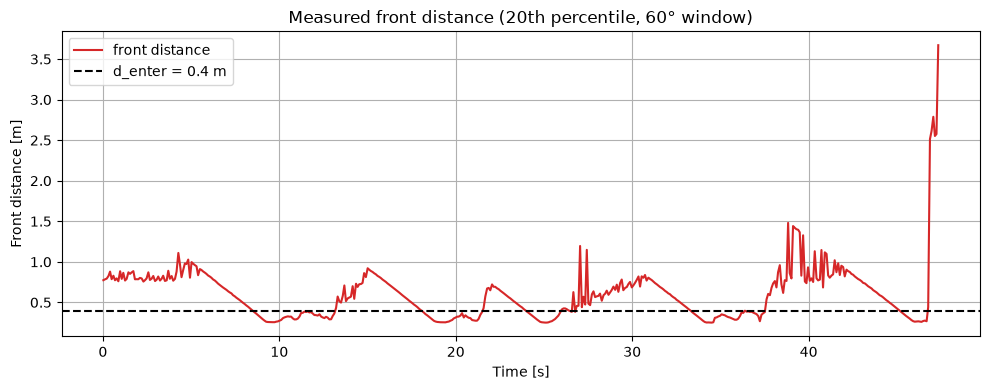

In [10]:
# %% Front distance from /scan (same computation as the controller)
D_ENTER = 0.40          # controller threshold to start turning [m]
FRONT_WIDTH_DEG = 60    # front window width, centered on 0 deg
PERCENTILE = 20

con = sqlite3.connect(str(DB3_PATH))
scans = read_topic(con, '/scan')
con.close()


def front_distance(scan):
    r = np.asarray(scan.ranges, dtype=float)
    r = np.nan_to_num(r, nan=scan.range_max, posinf=scan.range_max, neginf=scan.range_max)
    r = np.clip(r, 0.0, scan.range_max)
    # index of angle 0, wrapped into the scan range
    ang = (0.0 - scan.angle_min) % (2 * np.pi) + scan.angle_min
    c = int(round((ang - scan.angle_min) / scan.angle_increment))
    n = int(round(np.deg2rad(FRONT_WIDTH_DEG / 2) / scan.angle_increment))
    idx = np.arange(c - n, c + n + 1) % len(r)
    return np.percentile(r[idx], PERCENTILE)


t_s = np.array([t - t0 for t, _ in scans])
front = np.array([front_distance(m) for _, m in scans])

fig3, ax3 = plt.subplots(figsize=(10, 4))
ax3.plot(t_s, front, color='tab:red', label='front distance')
ax3.axhline(D_ENTER, color='k', linestyle='--', label=f'd_enter = {D_ENTER} m')
ax3.set_xlabel('Time [s]')
ax3.set_ylabel('Front distance [m]')
ax3.set_title('Measured front distance (20th percentile, 60° window)')
ax3.grid(True)
ax3.legend()
fig3.tight_layout()
if SAVE_FIGURES:
    fig3.savefig('front_distance.png', dpi=150)

plt.show()

Total points projected: 89348


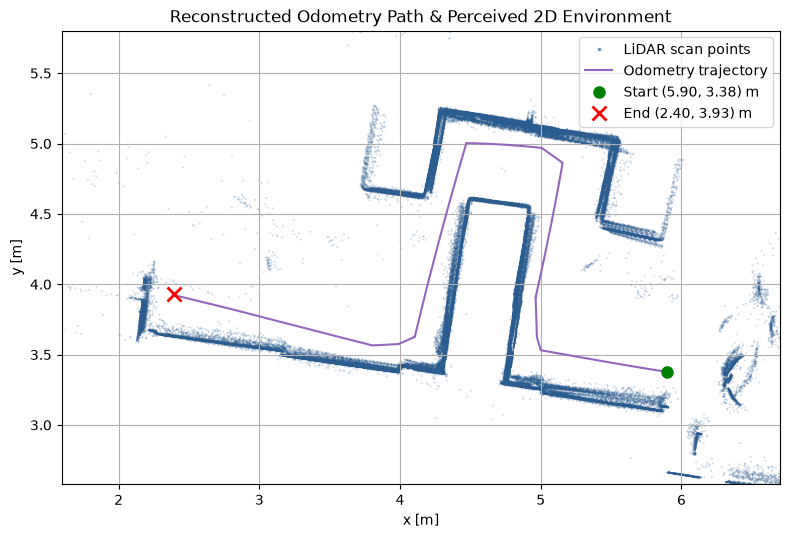

In [11]:
# %% Map: odometry path + accumulated LiDAR points
from matplotlib.lines import Line2D

LIDAR_OFFSET_X = -0.032   # LiDAR position in the base frame [m]
R_MIN, R_MAX = 0.12, 3.5   # valid range of the LDS-02 [m] (the real scan reports 0.0 and 100.0)

# load the scans if they are not already in memory (skip if the front-distance block ran)
if 'scans' not in globals():
    con = sqlite3.connect(str(DB3_PATH))
    scans = read_topic(con, '/scan')
    con.close()

pts_x, pts_y = [], []
for t, scan in scans:
    ts = t - t0
    # robot pose at the scan time, interpolated from /odom
    rx = np.interp(ts, t_o, x)
    ry = np.interp(ts, t_o, y)
    ryaw = np.interp(ts, t_o, yaw_unwrapped)

    r = np.asarray(scan.ranges, dtype=float)
    a = scan.angle_min + np.arange(len(r)) * scan.angle_increment
    ok = np.isfinite(r) & (r > R_MIN) & (r < R_MAX)
    r, a = r[ok], a[ok]

    # points in the base frame, then rotated/translated into the odom frame
    bx = r * np.cos(a) + LIDAR_OFFSET_X
    by = r * np.sin(a)
    pts_x.append(rx + bx * np.cos(ryaw) - by * np.sin(ryaw))
    pts_y.append(ry + bx * np.sin(ryaw) + by * np.cos(ryaw))

pts_x = np.concatenate(pts_x)
pts_y = np.concatenate(pts_y)
print(f'Total points projected: {len(pts_x)}')

# view limits around the trajectory (the data is not filtered, only the view is cropped)
MARGIN = 0.8   # [m] around the trajectory
xlim = (x.min() - MARGIN, x.max() + MARGIN)
ylim = (y.min() - MARGIN, y.max() + MARGIN)
w_in = 8.0
h_in = w_in * (ylim[1] - ylim[0]) / (xlim[1] - xlim[0]) + 1.0   # +1 in for labels/title

fig4, ax4 = plt.subplots(figsize=(w_in, h_in))
ax4.scatter(pts_x, pts_y, s=2.0, c='#2b5c8f', alpha=0.22, edgecolors='none')
ax4.plot(x, y, color='tab:purple', linewidth=1.5, zorder=5)
ax4.plot(x[0], y[0], 'go', markersize=8, zorder=7)
ax4.plot(x[-1], y[-1], 'rx', markersize=10, mew=2, zorder=7)

ax4.set_xlabel('x [m]')
ax4.set_ylabel('y [m]')
ax4.set_title('Reconstructed Odometry Path & Perceived 2D Environment')
ax4.set_xlim(xlim)
ax4.set_ylim(ylim)
ax4.set_aspect('equal', adjustable='box')
ax4.grid(True)

# legend with proxy handles: markers appear at their plot size (markerscale=1)
handles = [
    Line2D([], [], marker='.', linestyle='', color='#2b5c8f', alpha=0.6,
           markersize=3, label='LiDAR scan points'),
    Line2D([], [], color='tab:purple', linewidth=1.5, label='Odometry trajectory'),
    Line2D([], [], marker='o', linestyle='', color='g', markersize=8,
           label=f'Start ({x[0]:.2f}, {y[0]:.2f}) m'),
    Line2D([], [], marker='x', linestyle='', color='r', markersize=10, mew=2,
           label=f'End ({x[-1]:.2f}, {y[-1]:.2f}) m'),
]
ax4.legend(handles=handles, loc='best', markerscale=1.0)

fig4.tight_layout()
if SAVE_FIGURES:
    fig4.savefig('odometry_laser_map.png', dpi=150)

plt.show()